In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import linregress
from tqdm import tqdm

import MDAnalysis as mda
import MDAnalysis.transformations as trans

from run_state_diffusion import compute_state_dependent_diffusion, determine_membrane_bounds, determine_states

/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/Bio/Application/__init__.py:40: BiopythonDeprecationWarning: The Bio.Application modules and modules relying on it have been deprecated.

Due to the on going maintenance burden of keeping command line application
wrappers up to date, we have decided to deprecate and eventually remove these
modules.

We instead now recommend building your command line and invoking it directly
with the subprocess module.
  warnings.warn(


In [48]:
def verify_state_assignments(ag: mda.AtomGroup, states: np.ndarray, membrane_bounds: tuple, dt: float = None):
    """
    Randomly selects 3 water molecules and plots their Z-coordinates over time.
    Marker shapes indicate the specific molecule. Marker colors indicate the state.
    
    Parameters
    ----------
    ag : MDAnalysis.core.groups.AtomGroup
        The AtomGroup containing the water molecules.
    states : array_like
        A 2D array of states (1 for in-membrane, 0 for out-of-membrane).
        Expected shape is (n_frames, n_atoms) or (n_atoms, n_frames).
    membrane_bounds : list or tuple
        [lower_bound, upper_bound] for the membrane in the Z dimension (in Å).
    dt : float, optional
        Time step between frames in picoseconds. If None, it is extracted from the trajectory.
    """
    u = ag.universe
    n_frames = u.trajectory.n_frames
    n_atoms = len(ag)

    # Validate and reshape states array
    states = np.asarray(states)
    if states.shape == (n_atoms, n_frames):
        states = states.T
    elif states.shape != (n_frames, n_atoms):
        raise ValueError(f"Expected states array of shape ({n_frames}, {n_atoms}). Got {states.shape}.")

    # Determine time step
    if dt is None:
        dt = u.trajectory.dt
        if dt == 0.0:
            dt = 1.0  # Fallback if trajectory lacks dt metadata

    # Randomly select 3 distinct water molecules
    selected_indices = np.random.choice(n_atoms, 3, replace=False)

    # Extract Z-coordinates for the selected molecules
    z_coords = np.zeros((n_frames, 3), dtype=np.float32)
    for i, _ in enumerate(u.trajectory):
        z_coords[i, :] = ag.positions[selected_indices, 2]

    times = np.arange(n_frames) * dt

    # Setup plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    markers = ['o', 's', '^']
    state_colors = {0: 'royalblue', 1: 'crimson'}
    state_labels = {0: 'Bulk (0)', 1: 'Membrane (1)'}

    # Plot each molecule
    for i, atom_idx in enumerate(selected_indices):
        atom_z = z_coords[:, i]
        atom_states = states[:, atom_idx]
        
        # Plot each state separately to apply colors properly
        for state_val in [0, 1]:
            mask = (atom_states == state_val)
            if np.any(mask):
                # Only label the first instance to prevent legend duplication
                label = f"Mol {atom_idx} - {state_labels[state_val]}"
                ax.scatter(
                    times[mask], 
                    atom_z[mask], 
                    c=state_colors[state_val], 
                    marker=markers[i], 
                    label=label,
                    edgecolor='k',
                    alpha=0.7,
                    s=40
                )

    # Plot membrane bounds
    lower_bound, upper_bound = membrane_bounds
    ax.axhline(y=lower_bound, color='black', linestyle='--', linewidth=2, label='Membrane Lower Bound')
    ax.axhline(y=upper_bound, color='black', linestyle='--', linewidth=2, label='Membrane Upper Bound')

    ax.set_xlabel('Time (ps)')
    ax.set_ylabel('Z-coordinate (Å)')
    ax.set_title('Water Molecule Z-Coordinate State Verification')
    
    # Place legend outside the plot
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
    plt.tight_layout()

    return fig, ax

def validate_msd_calculation(ag: mda.AtomGroup, states: np.ndarray, dt: float = None, tolerance: int = 2, max_lines_to_plot: int = 500):
    """
    Validates partial, state-dependent MSD calculations by visualizing individual 
    trajectory segments, the average MSD, sampling statistics, and segmentation distribution.

    Parameters
    ----------
    ag : MDAnalysis.core.groups.AtomGroup
        The AtomGroup containing the particles of interest.
    states : array_like
        2D array of states (1 for in-state, 0 for out-of-state). Shape (n_frames, n_atoms).
    dt : float, optional
        Time step in picoseconds. If None, extracts from trajectory.
    tolerance : int, default=2
        Maximum consecutive frames a particle can be in state 0 and remain in the segment.
    max_lines_to_plot : int, default=500
        Maximum number of individual MSD lines to draw to prevent Matplotlib from hanging.

    Returns
    -------
    fig, axes : Matplotlib figure and axes objects.
    """
    u = ag.universe
    n_frames = u.trajectory.n_frames
    n_atoms = len(ag)

    if dt is None:
        dt = u.trajectory.dt
        if dt == 0.0: dt = 1.0 

    states = np.asarray(states)
    if states.shape == (n_atoms, n_frames):
        states = states.T

    # Pre-extract positions
    positions = np.zeros((n_frames, n_atoms, 3), dtype=np.float32)
    for i, _ in enumerate(u.trajectory):
        positions[i] = ag.positions

    def fill_gaps(state_array, tol):
        if tol == 0: return state_array
        filled = state_array.copy()
        zeros_idx = np.where(filled == 0)[0]
        if len(zeros_idx) == 0: return filled
        gaps = np.split(zeros_idx, np.where(np.diff(zeros_idx) != 1)[0] + 1)
        for gap in gaps:
            if 0 < len(gap) <= tol:
                if gap[0] > 0 and gap[-1] < len(filled) - 1:
                    if filled[gap[0]-1] == 1 and filled[gap[-1]+1] == 1:
                        filled[gap] = 1
        return filled

    sum_sq_disp = np.zeros(n_frames, dtype=np.float64)
    count_sq_disp = np.zeros(n_frames, dtype=np.int64)
    
    segments_per_molecule = []
    individual_msds = []

    for atom_idx in tqdm(range(n_atoms), desc="Computing MSDs"):
        atom_states = states[:, atom_idx]
        if tolerance > 0:
            atom_states = fill_gaps(atom_states, tolerance)
            
        padded = np.pad(atom_states, (1, 1), 'constant', constant_values=(0, 0))
        diffs = np.diff(padded)
        starts = np.where(diffs == 1)[0]
        ends = np.where(diffs == -1)[0]
        
        valid_segments = 0
        atom_pos = positions[:, atom_idx, :] 
        
        for s, e in zip(starts, ends):
            seg_len = e - s
            if seg_len < 2:
                continue 
            
            valid_segments += 1
            seg_pos = atom_pos[s:e]
            seg_msd = np.zeros(seg_len)
            
            for tau in range(1, seg_len):
                disp = seg_pos[tau:] - seg_pos[:-tau]
                sq_disp = np.sum(disp**2, axis=1)
                
                # Global accumulator for the ensemble average
                sum_sq_disp[tau] += np.sum(sq_disp)
                count_sq_disp[tau] += len(sq_disp)
                
                # Individual MSD for plotting
                seg_msd[tau] = np.mean(sq_disp)
                
            individual_msds.append((seg_msd, len(seg_msd)))
            
        segments_per_molecule.append(valid_segments)

    # Calculate global average MSD
    valid_tau = count_sq_disp > 0
    avg_msd = np.zeros(n_frames)
    avg_msd[valid_tau] = sum_sq_disp[valid_tau] / count_sq_disp[valid_tau]
    times = np.arange(n_frames) * dt

    # Plotting setup
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Panel 1: Individual and Average MSDs
    ax1 = axes[0]
    np.random.shuffle(individual_msds) # Shuffle so subset represents the whole distribution
    plotted = 0
    for seg_msd, length in individual_msds:
        if plotted >= max_lines_to_plot:
            break
        ax1.plot(times[:length], seg_msd, color='gray', alpha=0.25, linewidth=0.5)
        plotted += 1
        
    ax1.plot(times[valid_tau], avg_msd[valid_tau], color='red', label='Average')
    ax1.set_xlabel('Lag Time, $\\tau$ (ps)')
    ax1.set_ylabel('MSD (Å$^2$)')
    ax1.set_title('Individual Trajectory segments vs Average')
    ax1.legend()

    # Panel 2: Number of contributing trajectories (samples) at each tau
    ax2 = axes[1]
    ax2.plot(times[valid_tau], count_sq_disp[valid_tau], color='blue', linewidth=2)
    ax2.set_xlabel('Lag Time, $\\tau$ (ps)')
    ax2.set_ylabel('Number of Samples')
    ax2.set_title('Contributing Samples vs Lag Time')
    ax2.grid(True, alpha=0.3)
    ax2.set_yscale('log')

    # Panel 3: Histogram of segments per molecule
    ax3 = axes[2]
    max_segs = max(segments_per_molecule) if segments_per_molecule else 1
    bins = np.arange(-0.5, max_segs + 1.5, 1)
    ax3.hist(segments_per_molecule, bins=bins, color='teal', edgecolor='black', alpha=0.7)
    ax3.set_xlabel('Number of Segments')
    ax3.set_ylabel('Number of Molecules')
    ax3.set_title('Distribution of Trajectory Segments\nper Water Molecule')
    ax3.set_xticks(np.arange(max_segs + 1, step=5))

    plt.tight_layout()

    return fig, axes

### Check states

In [3]:
u = mda.Universe('prod.tpr', 'prod_centered.xtc')
PA = u.select_atoms('resname PA*')
water = u.select_atoms('resname SOL')
ow = water.select_atoms('type OW')

Calculating density profiles: 100%|██████████| 4001/4001 [00:21<00:00, 188.00it/s]


Found 2 intersection points:
  Z = 26.50 Å, Density = 0.0508 amu/Å³
  Z = 118.07 Å, Density = 0.0520 amu/Å³
Membrane bounds (Z): [ 26.50190379  49.39451567  72.28712755  95.17973943 118.07235131]


Determining water states: 4001it [00:08, 459.95it/s]


(<Figure size 1000x600 with 1 Axes>,
 <AxesSubplot: title={'center': 'Water Molecule Z-Coordinate State Verification'}, xlabel='Time (ps)', ylabel='Z-coordinate (Å)'>)

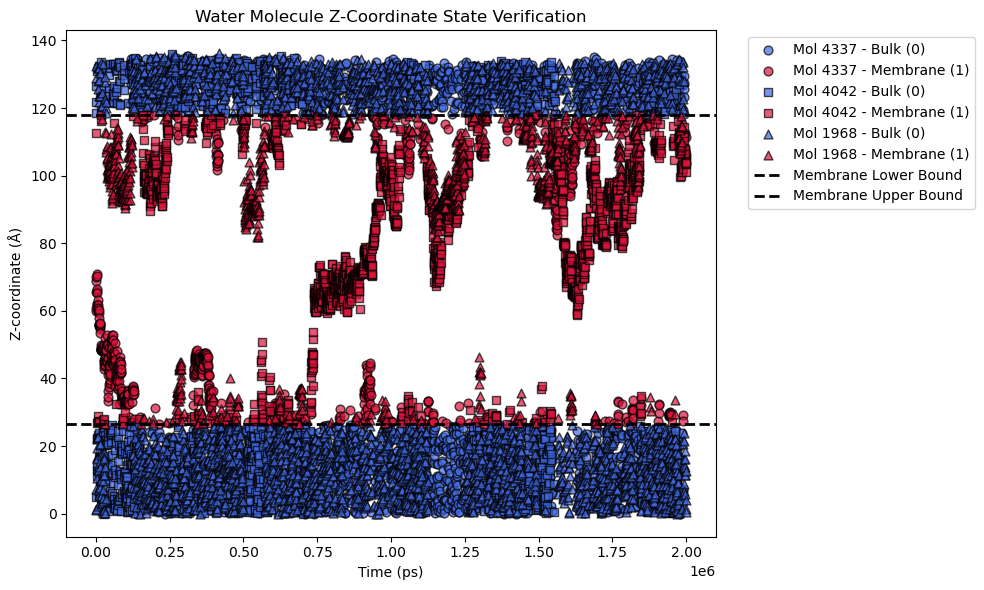

In [ ]:
# get geometric membrane boundaries
membrane_bounds = determine_membrane_bounds(PA, water, weighted='number', return_hist=False)

# get the time series of states for each water molecule
states = determine_states(ow, (membrane_bounds[0], membrane_bounds[-1]))

verify_state_assignments(ow, states, 
                         (membrane_bounds[0], membrane_bounds[-1]), 
                         dt=u.trajectory.dt)

### Test algorithm

In [5]:
def fill_gaps(state_array, tol):
    """Fills short gaps of 0s bounded by 1s."""
    if tol == 0:
        return state_array
    filled = state_array.copy()
    zeros_idx = np.where(filled == 0)[0]
    if len(zeros_idx) == 0:
        return filled

    # Split into consecutive blocks of 0s
    gaps = np.split(zeros_idx, np.where(np.diff(zeros_idx) != 1)[0] + 1)
    for gap in gaps:
        if 0 < len(gap) <= tol:
            # Ensure the gap is strictly bounded by 1s on both ends
            if gap[0] > 0 and gap[-1] < len(filled) - 1:
                if filled[gap[0]-1] == 1 and filled[gap[-1]+1] == 1:
                    filled[gap] = 1
    return filled

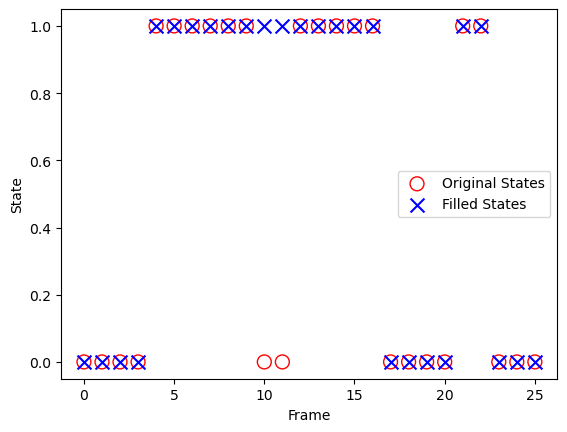

In [ ]:
# fill short gaps in "in membrane" states
test_states = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0])

tol = 2
filled_states = fill_gaps(test_states, tol)

plt.scatter(np.arange(len(test_states)), test_states, s=100, marker='o', facecolors='none', edgecolors='red', label='Original States')
plt.scatter(np.arange(len(filled_states)), filled_states, s=100, marker='x', color='blue', label='Filled States')
plt.xlabel('Frame')
plt.ylabel('State')
plt.legend()

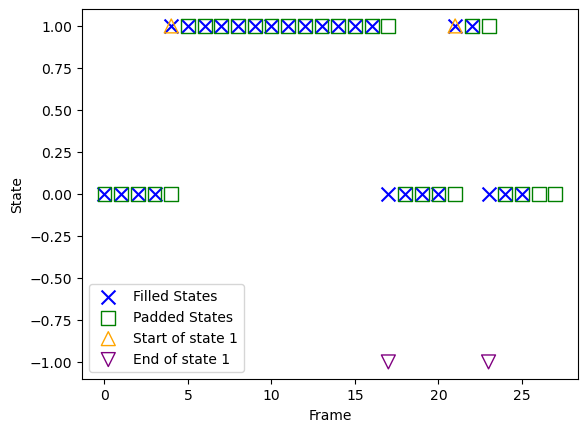

In [ ]:
# determine where continuous intervals of state 1 begin and end
padded = np.pad(filled_states, (1,1), 'constant', constant_values=(0,0))
diffs = np.diff(padded)
starts = np.where(diffs == 1)[0]
ends = np.where(diffs == -1)[0]

plt.scatter(np.arange(len(filled_states)), filled_states, s=100, marker='x', color='blue', label='Filled States')
plt.scatter(np.arange(len(padded)), padded, s=100, marker='s', edgecolor='green', facecolor='none', label='Padded States')
plt.scatter(np.arange(len(diffs))[starts], diffs[starts], s=100, marker='^', edgecolor='orange', facecolor='none', label='Start of state 1')
plt.scatter(np.arange(len(diffs))[ends], diffs[ends], s=100, marker='v', edgecolor='purple', facecolor='none', label='End of state 1')
plt.xlabel('Frame')
plt.ylabel('State')
plt.legend()

Extracting positions: 0it [00:00, ?it/s]

Extracting positions: 500it [00:01, 473.22it/s]


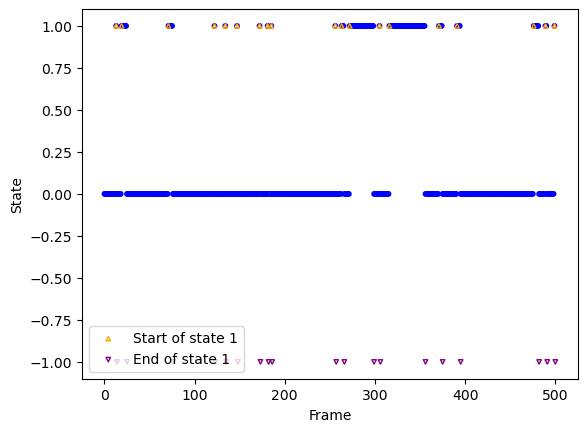

In [44]:
# get positions for one water
n_frames = 500
atom_idx = 0

tol = 2
filled_states = fill_gaps(states[:n_frames, atom_idx], tol)
padded = np.pad(filled_states, (1,1), 'constant', constant_values=(0,0))
diffs = np.diff(padded)
starts = np.where(diffs == 1)[0]
ends = np.where(diffs == -1)[0]

plt.scatter(np.arange(n_frames), filled_states, s=10, edgecolor='blue', facecolor='none')
plt.scatter(np.arange(len(diffs))[starts], diffs[starts], s=10, marker='^', edgecolor='orange', facecolor='none', label='Start of state 1')
plt.scatter(np.arange(len(diffs))[ends], diffs[ends], s=10, marker='v', edgecolor='purple', facecolor='none', label='End of state 1')

plt.xlabel('Frame')
plt.ylabel('State')
plt.legend()

# Extract all positions into memory (Assumes trajectory is already unwrapped to avoid PBC artifacts)
positions = np.zeros((n_frames, 1, 3), dtype=np.float32)
for i, _ in tqdm(enumerate(u.trajectory[:n_frames]), desc="Extracting positions"):
    positions[i,0,:] = ow.positions[0,:]

atom_pos = positions[:, atom_idx, :] 

In [47]:
# MSD for one segment
sum_sq_disp = np.zeros(n_frames, dtype=np.float64)
count_sq_disp = np.zeros(n_frames, dtype=np.int64)
msd = np.zeros(n_frames)

s,e = starts[1], ends[1]
seg_len = e - s
seg_pos = atom_pos[s:e]
print(f"Segment is of length {seg_len} from frame {s} to frame {e}\n")

for tau in range(1, seg_len):
    disp = seg_pos[tau:] - seg_pos[:-tau]
    sq_disp = np.sum(disp**2, axis=1)
    sum_sq_disp[tau] += np.sum(sq_disp)
    count_sq_disp[tau] += len(sq_disp)

valid_tau = count_sq_disp > 0
msd[valid_tau] = sum_sq_disp[valid_tau] / count_sq_disp[valid_tau]
print("Segment based algorithm:")
print(msd[valid_tau])
print()

# compared to tidynamics on that segment
import tidynamics
print("tidynamics algorithm:")
print(tidynamics.msd(seg_pos))

Segment is of length 6 from frame 19 to frame 25

Segment based algorithm:
[326.46564941 550.14447021 864.27473958 650.29980469 669.20306396]

tidynamics algorithm:
[-2.84388923e-04  3.26465893e+02  5.50144340e+02  8.64274716e+02
  6.50299824e+02  6.69201623e+02]


### Check MSDs

In [49]:
u = mda.Universe('prod.tpr', 'prod_nojump.xtc')
PA = u.select_atoms('resname PA*')
water = u.select_atoms('resname SOL')
ow = water.select_atoms('type OW')

Computing MSDs: 100%|██████████| 6120/6120 [06:44<00:00, 15.11it/s]


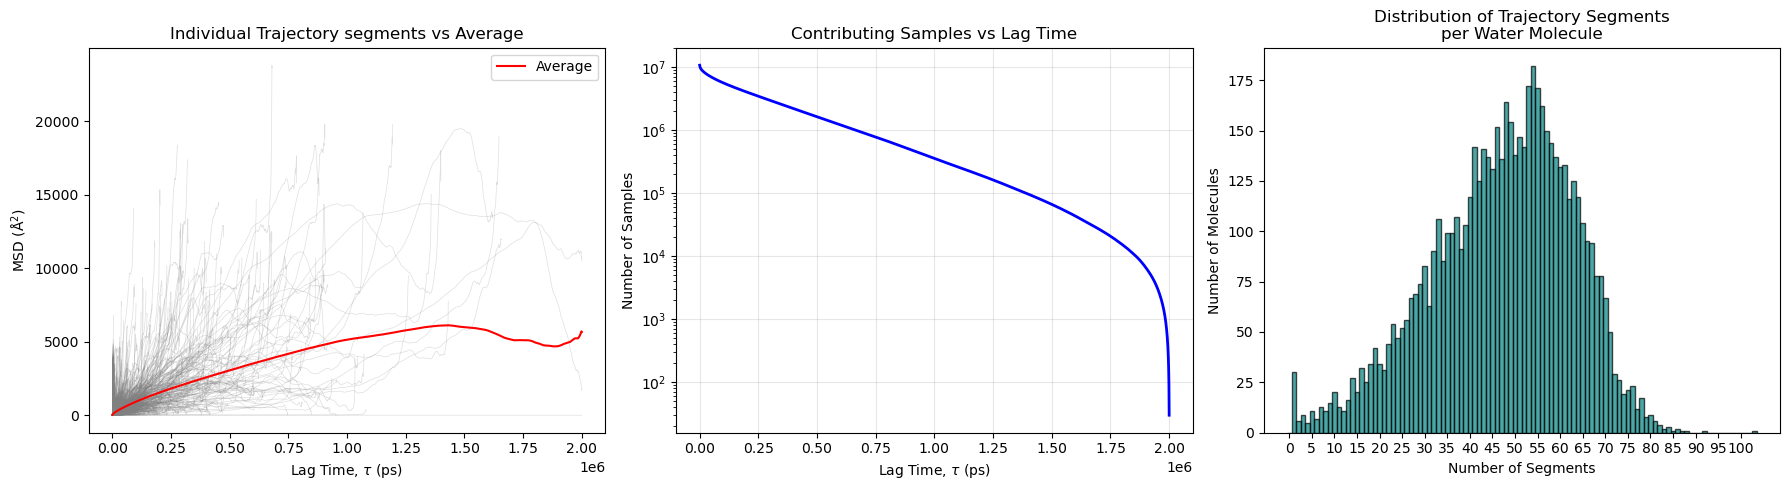

In [50]:
fig, ax = validate_msd_calculation(ow, states, 
                                   dt = u.trajectory.dt, 
                                   tolerance = 2, 
                                   max_lines_to_plot = 10_000)

Text(0, 0.5, 'MSD in membrane (nm$^2$)')

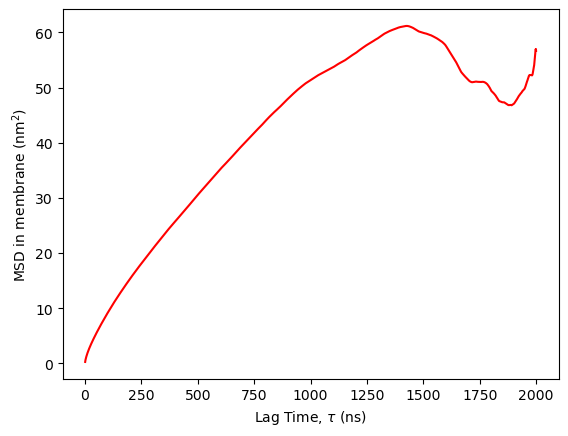

In [51]:
df = pd.read_csv('msd_all_membrane.csv')
plt.plot(df['Tau_ps'] / 1000, df['MSD_A2'] / 10**2, color='red')
plt.xlabel('Lag Time, $\\tau$ (ns)')
plt.ylabel('MSD in membrane (nm$^2$)')
# plt.xscale('log')
# plt.yscale('log')